# 컨텍스트와 토큰 예산

**이 노트북에서 할 일**

1. 한 번의 요청에 넣을 글 네 가지로 메시지 목록을 만들고, 목록에 실린 글만 이번 컨텍스트라는 것을 확인합니다.
2. 수업 예산에서 출력 예약분과 여유분을 먼저 빼고, 호출 전에 추정한 토큰 수를 실제 사용량과 비교합니다.
3. 입력을 먼저 채우고 남은 칸을 답에 준 Before와, 예약분을 먼저 뗀 After의 답을 비교합니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 없고, 글은 셀 안에 적습니다.

인터넷 서비스에 요청을 모두 3번 보냅니다. 모두 `gpt-5.4-mini`입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만으로 잡았습니다.
요금은 Ch 6 06절에서 2026-09-17에 확인한 mini 공식 요금 기준입니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
openai 3.8.0, tiktoken 0.14.0, python-dotenv 1.2.3도 함께 씁니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch08-context-engineering`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

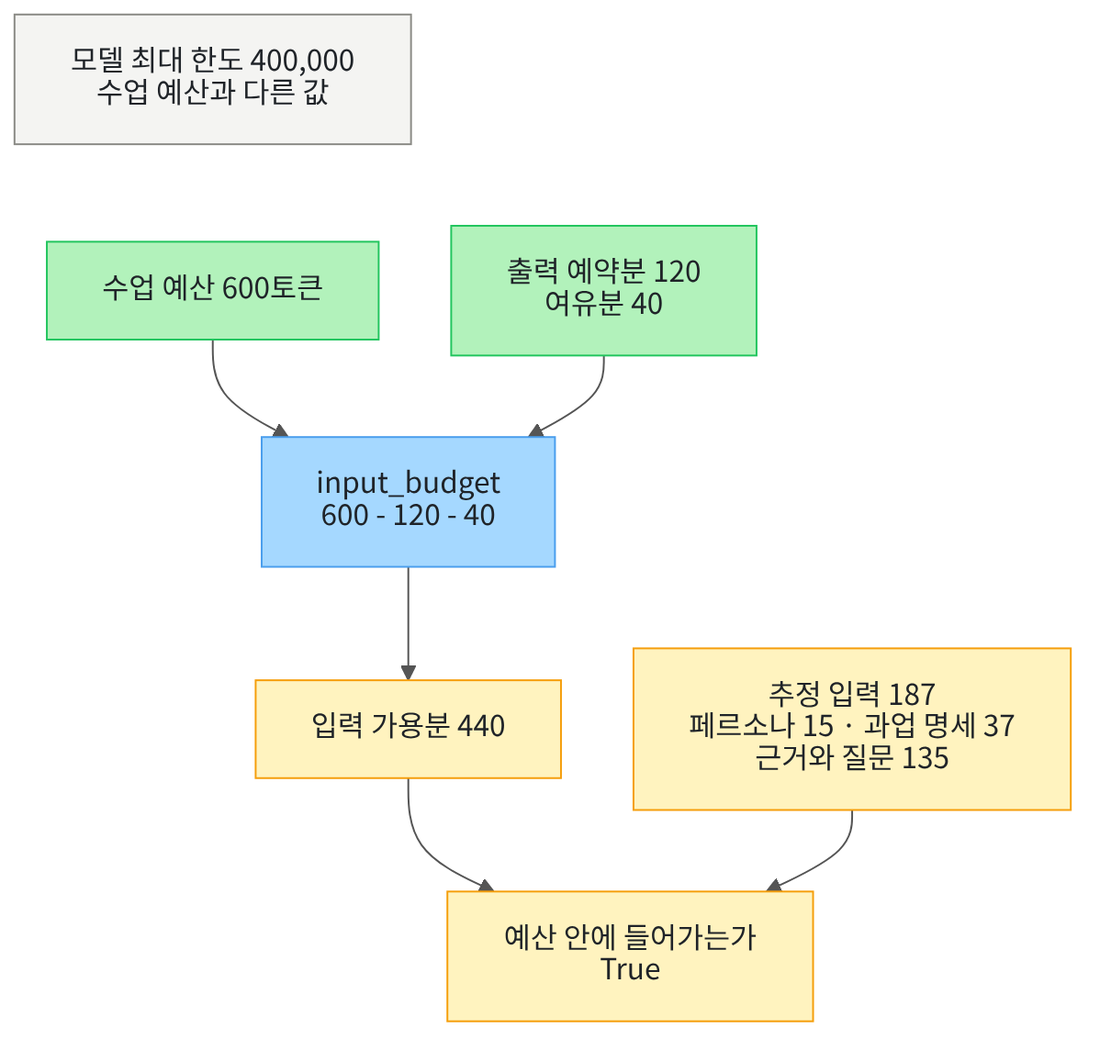

위에서 아래로 읽습니다. 초록 상자는 노트북 4절에서 정한 값이고, 파란 상자는 뺄셈 함수입니다.
노란 상자는 출력으로 확인한 값입니다. 입력 가용분 440과 5절의 추정 입력 187을 비교합니다.
맨 위 회색 상자는 모델이 받을 수 있는 최대 한도로, 이 노트북의 수업 예산과 다른 값입니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
Ch 7과 달리 토큰 수를 세는 라이브러리 tiktoken을 더 설치합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3" "tiktoken==0.14.0"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("tiktoken:", version("tiktoken"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.8.0
tiktoken: 0.14.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `openai: 3.8.0`, `tiktoken: 0.14.0` 등 여섯 줄입니다.
준비물에 적은 기준 버전과 같습니다. 이 챕터 실습 폴더의 openai 판은 Ch 7(3.10.0)과 다릅니다.

토큰 수를 세는 라이브러리와 모델 객체를 만드는 함수를 불러옵니다.

In [2]:
# 토큰 수를 세는 라이브러리와 모델 객체를 만드는 함수를 불러옵니다
import tiktoken

from langchain.chat_models import init_chat_model

Ch 7과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


Ch 7과 같은 설정으로 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.
마지막 줄은 Ch 6 01절에서 본 출력 상한(`max_tokens`)입니다. 이 객체에는 상한을 주지 않았습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다(출력 상한은 주지 않습니다)
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)
print("출력 상한(max_tokens):", model.max_tokens)

모델 이름: gpt-5.4-mini
temperature: 0.0
출력 상한(max_tokens): None


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`, `temperature: 0.0`, `출력 상한(max_tokens): None`입니다.
이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다. 실행마다 답 문장이 달라질 수 있습니다.
Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

## 2. 이번 요청에 넣을 글 네 가지

미르시립도서관 안내 문서(E01) 2쪽으로 질문 하나에 답하게 합니다. 이 도서관은 Ch 9에서도 쓰는 가상 기관입니다.
메시지 목록은 Ch 7과 같은 모양으로 만듭니다. system에는 페르소나, developer에는 과업 명세, user에는 근거와 질문을 넣습니다.

먼저 페르소나와 과업 명세 두 글을 만듭니다. 과업 명세는 근거만 쓰고, 두 문장 이내로 답하고, 출처를 적으라는 글입니다.

In [5]:
# system에 넣을 페르소나와 developer에 넣을 과업 명세를 만듭니다
persona_text = "당신은 미르시립도서관 안내 담당자입니다."
task_text = "주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 끝에 출처를 [E01 p.2]처럼 적으세요."
print("페르소나:", persona_text)
print("과업 명세:", task_text)

페르소나: 당신은 미르시립도서관 안내 담당자입니다.
과업 명세: 주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 끝에 출처를 [E01 p.2]처럼 적으세요.


**결과 읽기** — 두 줄은 `페르소나:`와 `과업 명세:`로 시작합니다. 과업 명세 줄에는 출처 표시 `[E01 p.2]`가 있습니다.
아직 글만 만들었고 요청은 보내지 않았습니다.

이번에는 근거와 질문을 만듭니다. 근거는 E01 문서 2쪽의 「2. 이용 시간」 문단입니다.
긴 글은 Ch 7 03절처럼 같은 이름에 `+`로 이어 다시 담습니다. 글 `"\n"`은 줄바꿈 한 번입니다.

In [6]:
# 근거로 쓸 E01 문서 2쪽 「이용 시간」 문단과 질문을 만듭니다
evidence_text = "[E01 p.2] 2. 이용 시간\n"
evidence_text = evidence_text + "평일(화~금) 이용 시간은 오전 9시부터 오후 10시까지입니다. "
evidence_text = evidence_text + "토요일과 일요일은 오전 9시부터 오후 6시까지 문을 엽니다.\n"
evidence_text = evidence_text + "매주 월요일은 정기 휴관일입니다. 법정 공휴일에도 휴관하며, "
evidence_text = evidence_text + "공휴일이 월요일과 겹치면 그 다음 날인 화요일에도 휴관합니다."
question_text = "미르시립도서관의 정기 휴관일은 언제이고, 공휴일이 월요일과 겹치면 어떻게 되나요?"
print("근거:")
print(evidence_text)
print("질문:", question_text)

근거:
[E01 p.2] 2. 이용 시간
평일(화~금) 이용 시간은 오전 9시부터 오후 10시까지입니다. 토요일과 일요일은 오전 9시부터 오후 6시까지 문을 엽니다.
매주 월요일은 정기 휴관일입니다. 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 그 다음 날인 화요일에도 휴관합니다.
질문: 미르시립도서관의 정기 휴관일은 언제이고, 공휴일이 월요일과 겹치면 어떻게 되나요?


**결과 읽기** — 라벨 줄 `근거:` 아래 세 줄이 근거 문단입니다. 셋째 줄에 `매주 월요일은 정기 휴관일입니다.`가 있습니다.
마지막 줄은 `질문:`으로 시작합니다. 질문에 답할 내용이 근거 셋째 줄에 모두 들어 있습니다.

같은 2쪽에는 이 질문에 쓰지 않는 자료도 있습니다. 「1. 도서관 소개」 문단과 구역별 이용 시간 표입니다.
두 글도 변수에 만들어 둡니다. 3절에서는 목록에 넣지 않고, 7절 값 바꿔 보기에서 넣습니다.

In [7]:
# 같은 2쪽에 있지만 이번 질문에 쓰지 않는 소개 문단과 구역 표를 만듭니다
intro_text = "[E01 p.2] 1. 도서관 소개\n"
intro_text = intro_text + "미르시립도서관은 1998년 10월 미르시 중앙동에 문을 연 공공도서관입니다. "
intro_text = intro_text + "지상 4층, 지하 1층 규모이며 장서 42만 권과 전자책 6만 종을 보유하고 있습니다. "
intro_text = intro_text + "2024년 리모델링을 마치고 3층에 '메이커 스페이스'와 '조용한 열람실'을 새로 열었습니다.\n"
intro_text = intro_text + "도서관의 사명은 \"누구나, 언제나, 무료로\"입니다. "
intro_text = intro_text + "시민 모두가 자료를 자유롭게 이용하고 배울 수 있도록 돕는 것을 최우선으로 합니다."
table_text = "[E01 p.2] 구역별 이용 시간(구역 | 평일 | 주말 | 비고)\n"
table_text = table_text + "종합자료실(2층) | 09:00~22:00 | 09:00~18:00 | 없음\n"
table_text = table_text + "어린이자료실(1층) | 09:00~18:00 | 09:00~18:00 | 보호자 동반 권장\n"
table_text = table_text + "디지털자료실(2층) | 09:00~21:00 | 09:00~18:00 | 1회 2시간\n"
table_text = table_text + "조용한 열람실(3층) | 07:00~22:00 | 07:00~18:00 | 좌석 예약제\n"
table_text = table_text + "메이커 스페이스(3층) | 13:00~20:00 | 13:00~17:00 | 사전 예약\n"
table_text = table_text + "카페 '책숲'(1층) | 09:00~20:00 | 09:00~17:00 | 외부 위탁"
print("소개 문단 글자 수:", len(intro_text))
print("구역 표 글자 수:", len(table_text))

소개 문단 글자 수: 240
구역 표 글자 수: 326


**결과 읽기** — 출력 줄은 `소개 문단 글자 수: 240`과 `구역 표 글자 수: 326`입니다. Ch 7 02절에서 본 것처럼 함수 `len()`에 글을 넣으면 글자 수입니다.
두 글은 노트북 변수에 있을 뿐, 아직 어느 메시지 목록에도 들어가지 않았습니다.

## 3. 메시지 목록과 이번 컨텍스트

user 메시지 글은 근거 문단 뒤에 빈 줄을 두고 질문을 붙여 만듭니다. 글 `"\n\n"`은 빈 줄 하나입니다(Ch 7 03절).
컨텍스트(context)는 모델이 이번 답을 만들 때 받은 글 전체입니다. 시험지에 인쇄된 지문만 풀이에 쓸 수 있는 것과 비슷합니다.
노트북 변수나 파일에 있어도 메시지 목록에 넣지 않은 글은 이번 컨텍스트가 아닙니다.

마지막 두 줄은 연산자 `in`(Ch 1)으로 소개 문단이 user 글 안에 들어 있는지 봅니다.
실행 전에 예상합니다. 메시지는 세 개이고, 소개 문단은 들어 있지 않을 것입니다.

In [8]:
# 근거와 질문을 이어 user 글을 만들고, Ch 7 모양의 메시지 목록을 만듭니다(요청은 보내지 않습니다)
user_text = evidence_text + "\n\n" + "질문: " + question_text
messages = [
    ("system", persona_text),
    ("developer", task_text),
    ("user", user_text),
]
print("메시지 수:", len(messages))
intro_included = intro_text in user_text
print("소개 문단이 이번 목록에 들어 있는가:", intro_included)
assert len(messages) == 3

메시지 수: 3
소개 문단이 이번 목록에 들어 있는가: False


**결과 읽기** — 출력 줄은 `메시지 수: 3`과 `소개 문단이 이번 목록에 들어 있는가: False`입니다. `assert`도 통과했습니다.
변수 `intro_text`는 노트북에 있지만 목록에 없으므로, 이 목록으로 보내는 요청의 컨텍스트가 아닙니다.
목록에 실린 페르소나·과업 명세·근거·질문 네 글이 이번 컨텍스트입니다.

## 4. 수업 예산표 — 출력 예약분과 여유분을 먼저 뗍니다

모델마다 한 번에 다룰 수 있는 토큰 수의 최대 한도(컨텍스트 윈도)가 있습니다. Ch 5 04절 칸막이 쟁반의 칸 전체입니다.
OpenAI 모델 안내(2026-09-17 확인)에 적힌 `gpt-5.4-mini`의 컨텍스트 윈도는 400,000토큰입니다. 최대 출력은 128,000토큰입니다.

최대 한도가 크다고 매번 그만큼 넣지는 않습니다. 사람이 이번 작업에 쓸 상한을 따로 정하는데, 이것을 토큰 예산(token budget)이라고 부릅니다.

이 노트북의 수업 예산은 600토큰입니다. 짧은 글로도 넘치는 모습을 보려고 작게 정한 연습용 값입니다.
예산에서 먼저 두 가지를 뗍니다. 출력 예약분(output reservation)은 답을 쓸 자리로 남겨 두는 토큰 수입니다.
여유분(safety margin)은 호출 전 추정이 실제보다 적게 나오는 몫을 받아 줄 빈자리입니다.

출력 예약분은 Ch 5 04절의 출력 몫, Ch 6 01절의 출력 상한과 같은 크기를 가리키는 이름입니다. 예산표에서는 예약분, 모델 설정에서는 출력 상한이라고 부릅니다.
먼저 세 값을 받아 입력 가용분을 반환하는 함수를 정의합니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [9]:
# 수업 예산에서 출력 예약분과 여유분을 빼, 입력에 쓸 수 있는 토큰 수를 반환하는 함수를 정의합니다
def input_budget(total_budget, output_reserve, safety_margin):
    available = total_budget - output_reserve - safety_margin
    return available

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

세 값을 이름 있는 변수에 담고 함수를 부릅니다. 계산은 `600 - 120 - 40`입니다.
실행 전에 예상합니다. 입력 가용분은 440일 것입니다.

In [10]:
# 수업 예산·출력 예약분·여유분을 정하고 입력 가용분을 계산합니다
total_budget = 600
output_reserve = 120
safety_margin = 40
available = input_budget(total_budget, output_reserve, safety_margin)
print("수업 예산:", total_budget)
print("출력 예약분:", output_reserve)
print("여유분:", safety_margin)
print("입력 가용분:", available)

수업 예산: 600
출력 예약분: 120
여유분: 40
입력 가용분: 440


**결과 읽기** — 네 줄은 `수업 예산: 600`, `출력 예약분: 120`, `여유분: 40`, `입력 가용분: 440`입니다.
입력에 넣을 네 글은 모두 합해 440토큰 안에 들어가야 합니다. 5절에서 네 글의 토큰 수를 셉니다.

## 5. 호출 전에 토큰 수 추정하기

모델은 글자가 아니라 토큰 단위로 셉니다. 토큰은 Ch 5 01절에서 「조각」이라고 부른 단위입니다.
라이브러리 tiktoken은 OpenAI 모델의 토큰화 규칙을 내 컴퓨터에서 쓰게 해 줍니다. 요청을 보내지 않고 셉니다.

함수 `tiktoken.encoding_for_model()`은 모델 이름을 받아 그 모델의 토큰화 규칙 객체를 반환합니다. 속성 `name`은 규칙 이름입니다.
메서드 `encode()`는 글을 받아 토큰 번호 목록을 반환합니다. Ch 5 01절의 `tokenizer.encode()`와 같은 일을 합니다.

실행 전에 예상합니다. 질문의 글자 수와 토큰 수는 같을까요?

In [11]:
# 모델 이름으로 토큰화 규칙을 불러오고, 질문 한 문장의 글자 수와 토큰 수를 비교합니다
encoding = tiktoken.encoding_for_model("gpt-5.4-mini")
print("토큰화 규칙 이름:", encoding.name)
question_ids = encoding.encode(question_text)
print("질문 글자 수:", len(question_text))
print("질문 토큰 수:", len(question_ids))

토큰화 규칙 이름: o200k_base
질문 글자 수: 45
질문 토큰 수: 32


**결과 읽기** — 출력 줄은 `토큰화 규칙 이름: o200k_base`, `질문 글자 수: 45`, `질문 토큰 수: 32`입니다.
같은 글이라도 글자 수와 토큰 수는 다릅니다. 그래서 예산표에는 글자 수가 아니라 토큰 수를 적습니다.

설치한 tiktoken 0.14.0 소스는 `gpt-5`로 시작하는 모델 이름에 이 규칙을 씁니다. Ch 5에서 센 Qwen 조각 수와는 규칙이 달라 나란히 비교하지 않습니다.
네 글을 차례로 세려고, 글 하나의 토큰 수를 반환하는 함수를 정의합니다. 함수는 위에서 만든 `encoding`을 읽습니다.

In [12]:
# 글 하나를 받아 토큰 수를 반환하는 함수를 정의합니다(바깥 이름 encoding을 읽습니다)
def count_tokens(text):
    token_ids = encoding.encode(text)
    return len(token_ids)

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

목록에 들어간 세 메시지의 글을 세어 예산표를 만듭니다. user 글에는 근거와 질문이 함께 들어 있습니다.
마지막 줄은 추정 입력 합계가 입력 가용분 안에 드는지 봅니다.
실행 전에 예상합니다. 글이 짧으니 440 안에 들어갈 것입니다.

In [13]:
# 세 메시지 글의 토큰 수를 세어 예산표를 만들고, 입력 가용분과 비교합니다
persona_tokens = count_tokens(persona_text)
task_tokens = count_tokens(task_text)
user_tokens = count_tokens(user_text)
estimated_input = persona_tokens + task_tokens + user_tokens
print("예산표(칸 | 추정 토큰 수):")
print("페르소나 |", persona_tokens)
print("과업 명세 |", task_tokens)
print("근거와 질문 |", user_tokens)
print("추정 입력 합계:", estimated_input)
fits = estimated_input <= available
print("입력 가용분 안에 드는가:", fits)

예산표(칸 | 추정 토큰 수):
페르소나 | 15
과업 명세 | 37
근거와 질문 | 135
추정 입력 합계: 187
입력 가용분 안에 드는가: True


**결과 읽기** — 라벨 줄 아래 세 줄은 `페르소나 | 15`, `과업 명세 | 37`, `근거와 질문 | 135`입니다.
그 아래 `추정 입력 합계: 187`과 `입력 가용분 안에 드는가: True`가 나왔습니다. 440 가운데 187을 씁니다.

이 수는 글 내용만 센 추정값입니다. 요청에는 역할 이름과 메시지 경계 표시도 함께 실립니다. 6절에서 실제 수와 비교합니다.

## 6. 실제로 보내고 사용량과 비교하기

3절 목록을 1절의 모델로 보냅니다. 답은 여러 줄일 수 있어 라벨 줄 `답:`을 따로 출력합니다.
실행 전에 예상합니다. 근거에 있는 월요일과 화요일 휴관이 답에 나올 것입니다.

In [14]:
# 3절 목록을 출력 상한 없는 모델로 보내고 답을 봅니다(요청 1번)
response = model.invoke(messages)
print("답:")
print(response.text)

답:
미르시립도서관의 정기 휴관일은 매주 월요일입니다. 공휴일이 월요일과 겹치면 그 다음 날인 화요일에도 휴관합니다. [E01 p.2]


**결과 읽기** — 라벨 줄 아래 답은 `미르시립도서관의 정기 휴관일은 매주 월요일입니다.`로 시작합니다.
둘째 문장에 `화요일에도 휴관합니다`가 있고, 끝에 출처 `[E01 p.2]`가 붙었습니다.
과업 명세대로 두 문장이고, 근거에 없는 내용은 없습니다. 근거의 「법정 공휴일에도 휴관」은 이번 답에 나오지 않았습니다.

응답의 사용량(`usage_metadata`, Ch 6 01절)에서 실제 입력·출력 토큰 수를 꺼내 추정값과 비교합니다.
끝난 이유(`finish_reason`)도 함께 봅니다. 마지막 두 줄은 차이와 출력이 각각 여유분·출력 예약분 안에 드는지 봅니다.
실행 전에 예상합니다. 실제 입력은 추정 187보다 조금 많을 것입니다.

In [15]:
# 실제 입력·출력 토큰 수를 꺼내, 추정값·여유분·출력 예약분과 비교합니다
usage = response.usage_metadata
actual_input = usage["input_tokens"]
actual_output = usage["output_tokens"]
print("실제 입력 토큰 수:", actual_input)
print("실제 출력 토큰 수:", actual_output)
print("끝난 이유:", response.response_metadata["finish_reason"])
input_gap = actual_input - estimated_input
print("실제 입력 - 추정 입력:", input_gap)
print("차이가 여유분 안에 드는가:", input_gap <= safety_margin)
print("출력이 출력 예약분 안에 드는가:", actual_output <= output_reserve)

실제 입력 토큰 수: 201
실제 출력 토큰 수: 52
끝난 이유: stop
실제 입력 - 추정 입력: 14
차이가 여유분 안에 드는가: True
출력이 출력 예약분 안에 드는가: True


**결과 읽기** — 출력 줄은 `실제 입력 토큰 수: 201`, `실제 출력 토큰 수: 52`, `끝난 이유: stop`입니다.
그 아래 `실제 입력 - 추정 입력: 14`, `차이가 여유분 안에 드는가: True`, `출력이 출력 예약분 안에 드는가: True`가 나왔습니다.

5절 추정은 글 내용만 셌고, 실제 입력은 14토큰 더 많았습니다. 메시지 세 개의 역할 이름과 경계 표시가 더해진 것으로 보입니다.
서비스 안에서 그 표시가 어떤 모양인지는 이번에 확인하지 않았습니다.
Ch 7 01절에서도 메시지가 1개에서 3개로 늘자, 같은 글자로 입력 토큰이 8개 늘었습니다. 여유분 40은 이런 차이를 받아 주는 자리입니다.

출력 52토큰도 출력 예약분 120 안에 들었습니다. 하지만 1절 모델에는 출력 상한이 없었습니다.
예약분을 지키게 한 것이 아니라, 이번 답이 짧아서 들어간 것입니다.

## 7. 값 바꿔 보기 — 같은 쪽의 다른 자료까지 넣기

바꾸는 값은 user 글 하나입니다. 근거 문단 앞에 소개 문단을, 뒤에 구역 표를 붙인 긴 목록을 만듭니다.
페르소나·과업 명세·질문과 수업 예산표는 그대로 둡니다. 이 셀은 목록을 만들고 세기만 하고, 요청을 보내지 않습니다.

실행 전에 예상합니다. 2절에서 두 글은 합해 566자였습니다. 추정 입력이 440을 넘을까요?

In [16]:
# 소개 문단과 구역 표까지 넣은 긴 목록을 만들고, 추정 입력을 입력 가용분과 비교합니다(요청은 보내지 않습니다)
long_user_text = intro_text + "\n\n" + evidence_text + "\n\n" + table_text + "\n\n" + "질문: " + question_text
long_messages = [
    ("system", persona_text),
    ("developer", task_text),
    ("user", long_user_text),
]
long_estimate = persona_tokens + task_tokens + count_tokens(long_user_text)
print("긴 목록 추정 입력 합계:", long_estimate)
print("입력 가용분:", available)
print("입력 가용분 안에 드는가:", long_estimate <= available)
overflow = long_estimate - available
print("넘친 토큰 수:", overflow)

긴 목록 추정 입력 합계: 570
입력 가용분: 440
입력 가용분 안에 드는가: False
넘친 토큰 수: 130


**결과 읽기** — 출력 줄은 `긴 목록 추정 입력 합계: 570`, `입력 가용분: 440`, `입력 가용분 안에 드는가: False`입니다.
마지막 줄은 `넘친 토큰 수: 130`입니다. 소개 문단과 구역 표가 목록에 들어가 이번 컨텍스트가 되자 383토큰이 늘었습니다.

질문에 답할 내용은 근거 문단에 이미 있었습니다. 더한 두 글은 답에 쓰이지 않으면서 입력 자리만 차지합니다.
이 예산표대로라면 긴 목록은 보내기 전에 줄여야 합니다. 무엇을 남길지 고르는 방법은 02절에서 다룹니다.

## 8. Before — 입력을 먼저 채우고, 남은 칸을 답에 주기

예산표를 거꾸로 쓰는 경우를 봅니다. 긴 목록을 그대로 넣고, 수업 예산 600에서 남은 칸을 답의 출력 상한으로 줍니다.
계산은 `600 - 570`입니다. 출력 상한을 준 모델 객체는 Ch 6 01절처럼 `max_tokens` 인자로 새로 만듭니다.

실행 전에 예상합니다. 남은 칸은 30이고, 6절 답은 그보다 길었으니 답이 중간에 끊길 것입니다.

In [17]:
# 긴 목록을 넣고 남은 칸을 출력 상한으로 준 모델 객체를 만듭니다(이 셀은 요청을 보내지 않습니다)
leftover_output = total_budget - long_estimate
print("답에 남은 칸:", leftover_output)
leftover_model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
    max_tokens=leftover_output,
)
print("출력 상한(max_tokens):", leftover_model.max_tokens)
assert leftover_model.max_tokens == leftover_output

답에 남은 칸: 30
출력 상한(max_tokens): 30


**결과 읽기** — 출력 줄은 `답에 남은 칸: 30`과 `출력 상한(max_tokens): 30`입니다. `assert`도 통과했습니다.

긴 목록을 이 모델 객체로 보냅니다. 답과 함께 끝난 이유와 실제 토큰 수를 봅니다.

In [18]:
# 긴 목록을 남은 칸만 준 모델로 보냅니다(요청 1번)
before_response = leftover_model.invoke(long_messages)
print("답:")
print(before_response.text)

답:
미르시립도서관의 정기 휴관일은 매주 월요일이며, 법정 공휴일에도 휴


**결과 읽기** — 라벨 줄 아래 답은 `미르시립도서관의 정기 휴관일은 매주 월요일이며, 법정 공휴일에도 휴`에서 끊겼습니다.
질문 둘째 부분인 「공휴일이 월요일과 겹치면」에 대한 답이 없고, 출처 표시도 없습니다. 오류는 나지 않았습니다.

In [19]:
# Before 요청의 토큰 수와 끝난 이유를 보고, 실제 합계를 수업 예산과 비교합니다
before_usage = before_response.usage_metadata
print("실제 입력 토큰 수:", before_usage["input_tokens"])
print("실제 출력 토큰 수:", before_usage["output_tokens"])
print("끝난 이유:", before_response.response_metadata["finish_reason"])
before_total = before_usage["input_tokens"] + before_usage["output_tokens"]
print("실제 합계:", before_total)
print("수업 예산을 넘었는가:", before_total > total_budget)

실제 입력 토큰 수: 584
실제 출력 토큰 수: 30
끝난 이유: length
실제 합계: 614
수업 예산을 넘었는가: True


**결과 읽기** — 출력 줄은 `실제 입력 토큰 수: 584`, `실제 출력 토큰 수: 30`, `끝난 이유: length`입니다.
그 아래 `실제 합계: 614`와 `수업 예산을 넘었는가: True`가 나왔습니다.

Ch 6 01절에서 본 것처럼 끝난 이유 `length`는 출력 상한에 닿아 멈췄다는 뜻입니다. 입력을 먼저 채우고 남은 30칸만 답에 주어 답이 끊겼습니다.
실제 입력도 추정 570보다 14 많은 584였습니다. 여유분 없이 남은 칸을 계산해서, 출력 상한을 지켜도 합계가 예산 600을 넘었습니다.

오류가 나지 않아 셀은 끝까지 실행됐습니다. 끊긴 답이 응답 객체에 그대로 담기므로, 답 글자와 함께 끝난 이유를 확인합니다.

## 9. After — 출력 예약분과 여유분을 먼저 떼기

고치는 곳은 예산표를 쓰는 순서입니다. 4절처럼 출력 예약분 120과 여유분 40을 먼저 떼어 입력 가용분 440을 구합니다.
보내기 전에 목록마다 추정 입력을 비교하면, 긴 목록이 넘친다는 것을 요청 전에 알 수 있습니다.
그래서 질문에 쓰는 근거만 남긴 3절 목록을 보내고, 출력 예약분을 모델의 출력 상한으로 줍니다.

실행 전에 예상합니다. 긴 목록은 `False`, 3절 목록은 `True`이고, 출력 상한은 120일 것입니다.

In [20]:
# 입력 가용분으로 두 목록을 먼저 검사하고, 출력 예약분을 출력 상한으로 준 모델 객체를 만듭니다
print("입력 가용분:", available)
print("긴 목록이 드는가:", long_estimate <= available)
print("3절 목록이 드는가:", estimated_input <= available)
reserved_model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
    max_tokens=output_reserve,
)
print("출력 상한(max_tokens):", reserved_model.max_tokens)
assert reserved_model.max_tokens == output_reserve

입력 가용분: 440
긴 목록이 드는가: False
3절 목록이 드는가: True
출력 상한(max_tokens): 120


**결과 읽기** — 출력 줄은 `입력 가용분: 440`, `긴 목록이 드는가: False`, `3절 목록이 드는가: True`입니다.
마지막 줄은 `출력 상한(max_tokens): 120`이고 `assert`도 통과했습니다. 예산표의 출력 예약분이 모델 설정에 그대로 들어갔습니다.

3절 목록을 이 모델 객체로 보냅니다.

In [21]:
# 입력 가용분 안에 드는 3절 목록을 출력 예약분만큼 상한을 준 모델로 보냅니다(요청 1번)
after_response = reserved_model.invoke(messages)
print("답:")
print(after_response.text)

답:
미르시립도서관의 정기 휴관일은 매주 월요일입니다. 공휴일이 월요일과 겹치면 그 다음 날인 화요일에도 휴관합니다. [E01 p.2]


**결과 읽기** — 라벨 줄 아래 답은 두 문장입니다. 둘째 문장에 `화요일에도 휴관합니다`, 끝에 `[E01 p.2]`가 있습니다.
질문의 두 부분에 모두 답했습니다. 이번 실행에서는 6절 답과 글자까지 같았지만, 늘 같다고 보장하지는 않습니다.

In [22]:
# After 요청의 토큰 수와 끝난 이유를 보고, 실제 합계를 수업 예산과 비교합니다
after_usage = after_response.usage_metadata
print("실제 입력 토큰 수:", after_usage["input_tokens"])
print("실제 출력 토큰 수:", after_usage["output_tokens"])
print("끝난 이유:", after_response.response_metadata["finish_reason"])
after_total = after_usage["input_tokens"] + after_usage["output_tokens"]
print("실제 합계:", after_total)
print("수업 예산 안에 드는가:", after_total <= total_budget)

실제 입력 토큰 수: 201
실제 출력 토큰 수: 52
끝난 이유: stop
실제 합계: 253
수업 예산 안에 드는가: True


**결과 읽기** — 출력 줄은 `실제 입력 토큰 수: 201`, `실제 출력 토큰 수: 52`, `끝난 이유: stop`입니다.
그 아래 `실제 합계: 253`과 `수업 예산 안에 드는가: True`가 나왔습니다.

입력 201은 6절과 같은 목록이라 같은 수입니다. 출력 상한 120이 있어도 답은 52토큰에서 끝났고, 끝난 이유는 모델이 스스로 멈춘 `stop`입니다.
예약분을 먼저 떼면, 답이 쓸 자리가 요청 전에 정해집니다. 긴 자료가 넘치는 것도 보내기 전에 알 수 있습니다.

## 정리

- 메시지 목록에 실린 페르소나·과업 명세·근거·질문만 이번 컨텍스트였고, 변수에만 있던 소개 문단은 아니었습니다.
- 수업 예산 600에서 출력 예약분 120과 여유분 40을 먼저 떼어 입력 가용분 440을 구했고, 추정 입력과 비교했습니다.
- 남은 칸 30을 답에 준 Before는 답이 끊겼고, 예약분을 출력 상한으로 준 After는 답을 끝까지 받았습니다.

다음 02절에서는 자료를 파일에 적어 두고, 질문에 필요한 기록만 골라 메시지에 넣습니다. 도서관 문서는 이 절과 같습니다.